# Triagem de sinistros suspeitos em seguro auto
> Projeto de portfólio com **dados sintéticos** (`data/auto_claims.csv`). A seguradora, os números e o contexto são fictícios.

## Entendimento do Negócio [Fase 1 - CRISP-DM]
Uma seguradora de automóveis fictícia precisa melhorar o processo de **perícia** de sinistros diante do risco de fraude.

**Cenário atual**
- Avisos de sinistro: cerca de 4 mil por mês (volume medido na Fase 2)
- Equipe de perícia: **32 peritos × 30 perícias/mês = 960 perícias/mês**
- **Política atual:** só entram na fila de perícia os sinistros com **valor pedido acima de R\$ 45 mil**, do maior para o menor valor, até o limite da capacidade.
- Custo de cada perícia, com ou sem fraude: **R\$ 700** (perito, deslocamento, atraso no pagamento). Cada perícia atrasa o pagamento em cerca de 7 dias.
- Custo de uma fraude paga sem perícia: **valor médio pedido nas fraudes** da base de treino (calculado na Fase 3).

**Premissa de negócio:** quando há fraude, a perícia sempre encontra, e o pagamento é negado.

Cada fraude paga sai do resultado da seguradora e volta para o preço dos segurados no ano seguinte, num mercado em que o cliente compara preço.

### Sete perguntas de tradução
1. **Decisão:** quais sinistros vão para a perícia, em casos mais qualificados que o corte atual (valor > R\$ 45 mil)
2. **Pergunta preditiva:** probabilidade de o aviso de sinistro ser fraude
3. **Unidade:** sinistro
4. **Alvo:** `is_fraud`
5. **Tarefa:** classificação binária
6. **Sinais (features):** `incident_date`, `incident_time`, `report_date`, `report_channel`, `claim_type`, `policy_tenure_days`, `prior_claims_12m`, `vehicle_age`, `vehicle_market_value`, `claimed_amount`, `police_report`, `third_party_identified` (*`state` e `policyholder_age` ficam fora do modelo final por risco de LGPD/discriminação; ver Fase 4*)
7. **Sucesso:**
   - dados: ROC AUC ≥ 0,85 em dados nunca vistos (teste = dezembro/2025)
   - negócio: custo esperado menor que o da política atual (falso negativo = fraude paga; **toda perícia custa R\$ 700, encontrando fraude ou não**)

## Entendimento dos Dados [Fase 2 - CRISP-DM]
### Bibliotecas e parâmetros do projeto (definidos uma única vez)

In [40]:
import warnings
warnings.filterwarnings('ignore', message='X does not have valid feature names')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.utils.validation import check_is_fitted
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score
import xgboost as xgb
import lightgbm as lgb
warnings.filterwarnings('ignore', message='IProgress not found')
import shap

# ---------------------------------------------------------------------------------
# Parâmetros do projeto (Fase 1)
# ---------------------------------------------------------------------------------
SEED = 42
np.random.seed(SEED)
ARQUIVO_BASE = 'data/auto_claims.csv'
COLUNA_ALVO = 'is_fraud'

CUSTO_PERICIA = 700                    # TODA perícia realizada (com ou sem fraude) custa R$ 700
PERICIAS_POR_PERITO_MES = 30           # produtividade de 1 perito
PERITOS_ATUAIS = 32                    # equipe atual
CAPACIDADE_PERICIA_MES = PERITOS_ATUAIS * PERICIAS_POR_PERITO_MES   # 960 perícias/mês
CORTE_POLITICA_ATUAL = 45000           # política atual: periciar claimed_amount > R$ 45 mil (maior -> menor)
# CUSTO_FN (fraude paga sem perícia) é calculado na Fase 3, a partir da base de treino

# Separação temporal pela data do aviso (report_date)
INICIO_TREINO, FIM_TREINO = '2025-01-01', '2025-11-30'
INICIO_TESTE, FIM_TESTE = '2025-12-01', '2025-12-31'

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', None)
print(f'Capacidade atual: {PERITOS_ATUAIS} peritos x {PERICIAS_POR_PERITO_MES} = {CAPACIDADE_PERICIA_MES} perícias/mês '
      f'| corte da política atual: R$ {CORTE_POLITICA_ATUAL:,.0f}'.replace(',', '.'))

Capacidade atual: 32 peritos x 30 = 960 perícias/mês | corte da política atual: R$ 45.000


In [41]:
df = pd.read_csv(ARQUIVO_BASE)
display(df.head())
print('Linhas x colunas:', df.shape)

# Cópia para a análise exploratória (as conversões da Fase 2 NÃO alteram o df original)
df_estudo = df.copy()

,claim_id,incident_date,incident_time,report_date,report_channel,claim_type,state,policyholder_age,policy_tenure_days,prior_claims_12m,vehicle_age,vehicle_market_value,claimed_amount,police_report,third_party_identified,paid_amount,is_fraud
0,CLM-488878,2025-10-09,19:37,2025-10-11,broker,collision,MG,27,1562,1,9,36700.0,"4366,13",yes,no,1546.51,0
1,CLM-692720,2025-04-09,18:36,2025-04-13,broker,glass,DF,70,1240,0,10,40300.0,"1557,12",no,not_applicable,1322.84,0
2,CLM-162932,2025-02-21,12:23,2025-02-23,app,glass,SP,34,2820,0,4,45700.0,"80,00",yes,not_applicable,0.00,0
3,CLM-613376,2025-06-06,12:36,2025-06-09,app,third_party_liability,RS,43,45,1,2,34500.0,"1721,70",no,no,1721.70,0
4,CLM-460925,2025-03-24,13:56,2025-03-25,call_center,theft,CE,47,1664,0,3,56200.0,"55332,03",yes,not_applicable,55332.03,0


Linhas x colunas: (50000, 17)


In [42]:
df_estudo.info()
'''
Pontos identificados:
1 - police_report tem nulos (entendimento de negócio: vazio = segurado não informou o BO)
2 - claimed_amount está como texto (vírgula decimal) e precisa virar float
3 - incident_date, incident_time e report_date estão como texto e precisam virar data/hora
'''

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   claim_id                50000 non-null  object 
 1   incident_date           50000 non-null  object 
 2   incident_time           50000 non-null  object 
 3   report_date             50000 non-null  object 
 4   report_channel          50000 non-null  object 
 5   claim_type              50000 non-null  object 
 6   state                   50000 non-null  object 
 7   policyholder_age        50000 non-null  int64  
 8   policy_tenure_days      50000 non-null  int64  
 9   prior_claims_12m        50000 non-null  int64  
 10  vehicle_age             50000 non-null  int64  
 11  vehicle_market_value    50000 non-null  float64
 12  claimed_amount          50000 non-null  object 
 13  police_report           47510 non-null  object 
 14  third_party_identified  50000 non-null

'\nPontos identificados:\n1 - police_report tem nulos (entendimento de negócio: vazio = segurado não informou o BO)\n2 - claimed_amount está como texto (vírgula decimal) e precisa virar float\n3 - incident_date, incident_time e report_date estão como texto e precisam virar data/hora\n'

### Funções auxiliares da análise exploratória

In [43]:
def converter_valor_br(serie: pd.Series) -> pd.Series:
    '''Converte texto no formato brasileiro ('20387,95' ou '1.234,56') para float. Valor já numérico passa direto.'''
    if pd.api.types.is_numeric_dtype(serie):
        return serie.astype(float)
    return pd.to_numeric(serie.astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False),
                         errors='coerce')


def taxa_fraude_geral(df_base: pd.DataFrame, exibir: bool = False) -> float:
    '''Taxa de fraude geral (fraudes / total de sinistros), como fração.'''
    total = len(df_base)
    fraudes = int(df_base[COLUNA_ALVO].sum())
    taxa = fraudes / total
    if exibir:
        print(f'Total de sinistros: {total:,} | Fraudes: {fraudes:,} | Taxa de fraude: {taxa:.2%} | '
              f'1 fraudador para cada {(total - fraudes) / fraudes:.1f} honestos'.replace(',', '.'))
    return taxa


def taxa_fraude_por_categoria(df_base: pd.DataFrame, coluna: str, rotulo_nulo: str = 'Em branco',
                              ordenar_por_taxa: bool = False) -> pd.DataFrame:
    '''Quantidade, fraudes, taxa de fraude, % da base, % das fraudes e risco relativo de cada categoria.'''
    taxa_base = taxa_fraude_geral(df_base)
    categoria = df_base[coluna].fillna(rotulo_nulo)
    tabela = df_base.groupby(categoria).agg(qtd=(COLUNA_ALVO, 'count'), fraudes=(COLUNA_ALVO, 'sum'),
                                            taxa_fraude_pct=(COLUNA_ALVO, 'mean'))
    tabela['taxa_fraude_pct'] *= 100
    tabela['pct_da_base_%'] = tabela['qtd'] / tabela['qtd'].sum() * 100
    tabela['pct_das_fraudes_%'] = tabela['fraudes'] / tabela['fraudes'].sum() * 100
    tabela['risco_vs_base'] = tabela['taxa_fraude_pct'] / (taxa_base * 100)
    if ordenar_por_taxa:
        tabela = tabela.sort_values('taxa_fraude_pct', ascending=False)
    return tabela.round(2)


def taxa_por_faixa_quantil(serie: pd.Series, nome: str, n_faixas: int = 10,
                           df_base: pd.DataFrame | None = None) -> pd.DataFrame:
    '''Taxa de fraude por decil, com intervalo de confiança de 95% (Wilson).'''
    df_base = df_estudo if df_base is None else df_base
    taxa_base = taxa_fraude_geral(df_base)
    faixa = pd.qcut(serie, q=n_faixas, duplicates='drop')
    t = df_base.groupby(faixa, observed=True)[COLUNA_ALVO].agg(qtd='size', fraudes='sum')
    p = t['fraudes'] / t['qtd']; n = t['qtd']; z = 1.96
    centro = (p + z**2 / (2*n)) / (1 + z**2 / n)
    margem = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / (1 + z**2 / n)
    t['taxa_%'] = (p * 100).round(2)
    t['ic95_inf_%'] = ((centro - margem) * 100).round(2)
    t['ic95_sup_%'] = ((centro + margem) * 100).round(2)
    t['risco_vs_base'] = (p / taxa_base).round(2)
    t.index = [f'{iv.left/1000:,.1f}k – {iv.right/1000:,.1f}k' for iv in t.index]
    rho, pval = spearmanr(serie, df_base[COLUNA_ALVO])
    print(f'\n=== {nome}: taxa de fraude por decil === (taxa média = {taxa_base*100:.2f}%) | '
          f'Spearman = {rho:.4f} (p = {pval:.2e})')
    print(t.to_string())
    return t

In [44]:
# Conversões usadas na exploração (datas com formato explícito)
for col in ['claimed_amount', 'vehicle_market_value', 'paid_amount']:
    df_estudo[col] = converter_valor_br(df_estudo[col])
df_estudo['incident_date'] = pd.to_datetime(df_estudo['incident_date'], format='%Y-%m-%d', errors='coerce')
df_estudo['report_date'] = pd.to_datetime(df_estudo['report_date'], format='%Y-%m-%d', errors='coerce')

print('claimed_amount que não converteu:', df_estudo['claimed_amount'].isna().sum())
print('Datas que não converteram -> aviso:', df_estudo['report_date'].isna().sum(),
      '| ocorrência:', df_estudo['incident_date'].isna().sum())

claimed_amount que não converteu: 0
Datas que não converteram -> aviso: 0 | ocorrência: 0


In [45]:
df_estudo.describe(include='all')

,claim_id,incident_date,incident_time,report_date,report_channel,claim_type,state,policyholder_age,policy_tenure_days,prior_claims_12m,vehicle_age,vehicle_market_value,claimed_amount,police_report,third_party_identified,paid_amount,is_fraud
count,50000,50000,50000,50000,50000,50000,50000,50000.00000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,47510,50000,50000.000000,50000.000000
unique,50000,NaN,1440,NaN,3,6,27,NaN,NaN,NaN,NaN,NaN,NaN,2,3,NaN,NaN
top,CLM-103028,NaN,14:15,NaN,app,collision,SP,NaN,NaN,NaN,NaN,NaN,NaN,no,yes,NaN,NaN
freq,1,NaN,93,NaN,21395,25072,14135,NaN,NaN,NaN,NaN,NaN,NaN,24079,20343,NaN,NaN
mean,NaN,2025-06-27 21:42:58.176000,NaN,2025-06-29 00:43:36.192000256,NaN,NaN,NaN,43.13586,1041.346000,0.219600,5.97046,54929.614000,13416.286548,NaN,NaN,10087.323671,0.030220
min,NaN,2025-01-01 00:00:00,NaN,2025-01-01 00:00:00,NaN,NaN,NaN,18.00000,1.000000,0.000000,0.00000,12000.000000,80.000000,NaN,NaN,0.000000,0.000000
25%,NaN,2025-03-21 00:00:00,NaN,2025-03-22 00:00:00,NaN,NaN,NaN,34.00000,440.000000,0.000000,3.00000,34000.000000,1844.260000,NaN,NaN,0.000000,0.000000
50%,NaN,2025-06-23 00:00:00,NaN,2025-06-24 00:00:00,NaN,NaN,NaN,43.00000,833.000000,0.000000,5.00000,48300.000000,5285.830000,NaN,NaN,1736.295000,0.000000
75%,NaN,2025-10-05 00:00:00,NaN,2025-10-06 00:00:00,NaN,NaN,NaN,52.00000,1427.000000,0.000000,8.00000,68200.000000,14647.692500,NaN,NaN,9127.765000,0.000000
max,NaN,2025-12-31 00:00:00,NaN,2026-01-06 00:00:00,NaN,NaN,NaN,85.00000,5000.000000,4.000000,25.00000,439500.000000,667553.220000,NaN,NaN,664418.910000,1.000000


### Taxa de fraude geral e por variável categórica

In [46]:
taxa = taxa_fraude_geral(df_estudo, exibir=True)
print('\npolice_report:'); print(taxa_fraude_por_categoria(df_estudo, 'police_report'))
# Premissa: police_report vazio = segurado não informou o BO. Todo pedido é considerado (sem descarte de linhas).

Total de sinistros: 50.000 | Fraudes: 1.511 | Taxa de fraude: 3.02% | 1 fraudador para cada 32.1 honestos

police_report:
                 qtd  fraudes  taxa_fraude_pct  pct_da_base_%  pct_das_fraudes_%  risco_vs_base
police_report                                                                                  
Em branco       2490       79             3.17           4.98               5.23           1.05
no             24079     1073             4.46          48.16              71.01           1.47
yes            23431      359             1.53          46.86              23.76           0.51


In [47]:
print('report_channel:'); print(taxa_fraude_por_categoria(df_estudo, 'report_channel'))
print('\nthird_party_identified:'); print(taxa_fraude_por_categoria(df_estudo, 'third_party_identified'))
print('\nstate:'); print(taxa_fraude_por_categoria(df_estudo, 'state', ordenar_por_taxa=True))

report_channel:
                  qtd  fraudes  taxa_fraude_pct  pct_da_base_%  pct_das_fraudes_%  risco_vs_base
report_channel                                                                                  
app             21395      583             2.72          42.79              38.58           0.90
broker          18025      367             2.04          36.05              24.29           0.67
call_center     10580      561             5.30          21.16              37.13           1.75

third_party_identified:
                          qtd  fraudes  taxa_fraude_pct  pct_da_base_%  pct_das_fraudes_%  risco_vs_base
third_party_identified                                                                                  
no                       9749      573             5.88          19.50              37.92           1.94
not_applicable          19908      139             0.70          39.82               9.20           0.23
yes                     20343      799             3.9

In [48]:
# Fraude, valores médios e relação pedido/valor de mercado por tipo de sinistro
tabela_tipo = df_estudo.groupby('claim_type').agg(
    qtd=('claim_type', 'count'), fraudes=(COLUNA_ALVO, 'sum'), taxa_fraude_pct=(COLUNA_ALVO, 'mean'),
    valor_mercado_medio=('vehicle_market_value', 'mean'), pedido_medio=('claimed_amount', 'mean'),
    pago_medio=('paid_amount', 'mean'))
tabela_tipo['taxa_fraude_pct'] *= 100
tabela_tipo['pedido_vs_mercado_%'] = tabela_tipo['pedido_medio'] / tabela_tipo['valor_mercado_medio'] * 100
tabela_tipo['pago_vs_pedido_%'] = tabela_tipo['pago_medio'] / tabela_tipo['pedido_medio'] * 100
tabela_tipo['risco_vs_base'] = tabela_tipo['taxa_fraude_pct'] / (df_estudo[COLUNA_ALVO].mean() * 100)
print(tabela_tipo.sort_values('qtd', ascending=False).round(2))

                         qtd  fraudes  taxa_fraude_pct  valor_mercado_medio  pedido_medio  pago_medio  pedido_vs_mercado_%  pago_vs_pedido_%  risco_vs_base
claim_type                                                                                                                                                 
collision              25072     1321             5.27             54954.74       9722.87     5399.77                17.69             55.54           1.74
glass                  10399        5             0.05             54690.12       1265.45      903.98                 2.31             71.43           0.02
theft                   5057       22             0.44             54886.45      50914.80    45236.98                92.76             88.85           0.14
third_party_liability   5020       51             1.02             55668.61       7847.29     6872.00                14.10             87.57           0.34
flood                   2934       87             2.97          

### Outliers: onde estão, por que existem e se precisam de tratamento
O critério IQR marca como outlier o que fica fora de [Q1 − k·IQR, Q3 + k·IQR]. Ser outlier no critério **não quer dizer erro**: é preciso olhar a causa e se a taxa de fraude muda nesses casos.

In [49]:
def diagnostico_outliers(df_base: pd.DataFrame, colunas, k: float = 1.5) -> pd.DataFrame:
    '''Para cada variável: limites do IQR, quantidade de outliers, assimetria e taxa de fraude dentro x fora.'''
    linhas = []
    for col in colunas:
        s = df_base[col]
        q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
        inf, sup = q1 - k * iqr, q3 + k * iqr
        fora = (s < inf) | (s > sup)
        linhas.append({'variável': col, 'Q1': q1, 'Q3': q3, 'IQR': iqr, 'limite sup.': sup,
                       'outliers': int(fora.sum()), '% da base': fora.mean() * 100,
                       'acima/abaixo': f'{int((s > sup).sum())}/{int((s < inf).sum())}',
                       'assimetria': s.skew(),
                       'fraude outliers (%)': df_base.loc[fora, COLUNA_ALVO].mean() * 100 if fora.any() else np.nan,
                       'fraude restante (%)': df_base.loc[~fora, COLUNA_ALVO].mean() * 100})
    t = pd.DataFrame(linhas).set_index('variável')
    t['risco outliers/restante'] = t['fraude outliers (%)'] / t['fraude restante (%)']
    return t.round(2)


colunas_numericas = df_estudo.select_dtypes('number').columns.drop(COLUNA_ALVO)
for k in (1.5, 3):
    print(f'\n=== k = {k} ===')
    print(diagnostico_outliers(df_estudo, colunas_numericas, k).to_string())


=== k = 1.5 ===
                            Q1        Q3       IQR  limite sup.  outliers  % da base acima/abaixo  assimetria  fraude outliers (%)  fraude restante (%)  risco outliers/restante
variável                                                                                                                                                                        
policyholder_age         34.00     52.00     18.00        79.00       115       0.23        115/0        0.14                 3.48                 3.02                     1.15
policy_tenure_days      440.00   1427.00    987.00      2907.50      1778       3.56       1778/0        1.45                 2.70                 3.03                     0.89
prior_claims_12m          0.00      0.00      0.00         0.00      9877      19.75       9877/0        2.13                 3.83                 2.82                     1.36
vehicle_age               3.00      8.00      5.00        15.50      1259       2.52       1259/0 

In [50]:
# 1) prior_claims_12m: Q1 = Q3 = 0 -> IQR = 0, então QUALQUER valor diferente de zero vira "outlier"
print('prior_claims_12m: distribuição e taxa de fraude')
print(df_estudo.groupby('prior_claims_12m')[COLUNA_ALVO]
      .agg(qtd='count', taxa_fraude='mean').assign(taxa_fraude=lambda t: (t['taxa_fraude'] * 100).round(2)))

prior_claims_12m: distribuição e taxa de fraude
                    qtd  taxa_fraude
prior_claims_12m                    
0                 40123         2.82
1                  8855         3.76
2                   947         4.44
3                    69         4.35
4                     6         0.00


In [ ]:
# 2) claimed_amount: a assimetria vem da MISTURA de tipos de sinistro (vidro custa centenas; roubo e incêndio, o carro inteiro)
q1_geral, q3_geral = df_estudo['claimed_amount'].quantile([0.25, 0.75])
fora_geral = df_estudo['claimed_amount'] > q3_geral + 1.5 * (q3_geral - q1_geral)
print('Composição dos outliers de claimed_amount (IQR geral, k=1,5) por tipo de sinistro (%):')
print((df_estudo.loc[fora_geral, 'claim_type'].value_counts(normalize=True) * 100).round(1).to_string())

# Outliers calculados DENTRO de cada tipo (comparando colisão com colisão, vidro com vidro...)
linhas = []
for tipo, g in df_estudo.groupby('claim_type'):
    q1, q3 = g['claimed_amount'].quantile([0.25, 0.75])
    fora = g['claimed_amount'] > q3 + 1.5 * (q3 - q1)
    linhas.append({'claim_type': tipo, 'mediana pedido (R$)': round(g['claimed_amount'].median()),
                   'limite sup. no tipo (R$)': round(q3 + 1.5 * (q3 - q1)), 'outliers no tipo': int(fora.sum()),
                   'fraude outliers (%)': round(g.loc[fora, COLUNA_ALVO].mean() * 100, 2),
                   'fraude restante (%)': round(g.loc[~fora, COLUNA_ALVO].mean() * 100, 2)})
print('\nOutliers de claimed_amount dentro de cada tipo de sinistro:')
print(pd.DataFrame(linhas).sort_values('mediana pedido (R$)').to_string(index=False))

# 3) Pedido acima do valor de mercado do veículo: o único caso com cara de erro de digitação
acima = df_estudo['claimed_amount'] > df_estudo['' \
'_market_value']
print(f'\nPedido > valor de mercado: {acima.sum()} casos ({acima.mean():.2%}) | '
      f'taxa de fraude {df_estudo.loc[acima, COLUNA_ALVO].mean():.2%} (base {df_estudo[COLUNA_ALVO].mean():.2%})')

Composição dos outliers de claimed_amount (IQR geral, k=1,5) por tipo de sinistro (%):
claim_type
theft                    59.3
fire                     17.8
collision                16.4
flood                     4.2
third_party_liability     2.0
glass                     0.3

Outliers de claimed_amount dentro de cada tipo de sinistro:
           claim_type  mediana pedido (R$)  limite sup. no tipo (R$)  outliers no tipo  fraude outliers (%)  fraude restante (%)
                glass                  723                      2841               787                 0.25                 0.03
third_party_liability                 4971                     19299               370                 3.78                 0.80
            collision                 5997                     24211              2000                16.40                 4.30
                flood                 9011                     35204               234                11.54                 2.22
                

**Conclusão sobre os outliers (k = 1,5)**

| Variável | Por que aparecem outliers | Fraude nos outliers | Tratamento |
|---|---|---|---|
| `prior_claims_12m` | **Artefato do método:** 80% dos segurados têm 0 sinistro, então Q1 = Q3 = 0 e o IQR é zero. Qualquer valor ≥ 1 vira "outlier" (19,8% da base) | Sobe com a contagem: 2,8% (0) → 3,8% (1) → 4,4% (2) | **Nenhum.** É uma contagem discreta e plausível, e carrega sinal de fraude |
| `claimed_amount` | **Mistura de tipos de sinistro:** roubo e incêndio pedem o valor do carro inteiro (mediana ≈ R\$ 44 mil), vidro pede centenas. Os outliers gerais são 77% roubo/incêndio | Dentro do mesmo tipo, os outliers concentram fraude: colisão 16,4% vs 4,3%; alagamento 11,5% vs 2,2% | **Nenhum.** É o sinal mais forte do modelo; cortar ou limitar apagaria justamente as fraudes |
| `vehicle_market_value` | Carros de alto valor (cauda longa natural de preço) | 3,7% vs 3,0% | **Nenhum** |
| `policy_tenure_days` | Clientes antigos (apólices com muitos anos); teto em 5000 dias | 2,7% vs 3,0%. O risco está na apólice **nova** (< 90 dias: 8,3%), não na cauda | **Nenhum** além da flag do teto (já criada na Fase 3) |
| `vehicle_age` | Veículos com mais de 16 anos; teto em 25 anos | 2,5% vs 3,0% | **Nenhum** além da flag do teto (já criada na Fase 3) |
| `policyholder_age` | Segurados acima de 79 anos (plausível); nenhum com k = 3 | 3,5% vs 3,0% | Sai do modelo final (variável sensível) |
| `paid_amount` | Indenizações de perda total | 0% (fraude quase sempre tem pagamento zero) | Sai do modelo (**vazamento**). Os outliers não importam |

**Por que não remover nem limitar (capping):**
1. **Os valores são plausíveis**, não erros de medida. A exceção são os poucos pedidos acima do valor de mercado do veículo, cuja taxa de fraude é igual à da base. Eles ficam na base, pois todo pedido precisa receber um score.
2. **Premissa de negócio:** todo aviso de sinistro precisa ser avaliado, então não dá para descartar linhas.
3. **Modelos de árvore** (Árvore, Random Forest, XGBoost, LightGBM) dividem os dados pela **ordem** dos valores. Um valor extremo não distorce o modelo como faria numa regressão linear, então padronizar ou limitar não traria ganho.
4. Nos valores, os outliers **são** o fenômeno que queremos detectar. Tratá-los como ruído reduziria a capacidade de encontrar fraude.

In [52]:
# Aviso antes da ocorrência? (inconsistência de datas)
inconsistentes = df_estudo[df_estudo['report_date'] < df_estudo['incident_date']]
print(f'Aviso antes da ocorrência: {len(inconsistentes)} casos ({len(inconsistentes)/len(df_estudo):.2%} da base)')

Aviso antes da ocorrência: 0 casos (0.00% da base)


In [53]:
# vehicle_age: teto em 25 anos
tabela_idade_veic = (df_estudo.groupby('vehicle_age')[COLUNA_ALVO]
                     .agg(qtd='count', fraudes='sum', taxa_fraude='mean')
                     .assign(taxa_fraude=lambda t: (t['taxa_fraude'] * 100).round(2)))
print(tabela_idade_veic.sort_index(ascending=False).head(8))

             qtd  fraudes  taxa_fraude
vehicle_age                           
25            52        0         0.00
24            24        0         0.00
23            34        3         8.82
22            39        1         2.56
21            65        4         6.15
20            83        1         1.20
19           130        2         1.54
18           201        6         2.99


In [54]:
# policy_tenure_days: teto em 5000 dias e faixas de tempo de apólice
contagem_dias = df_estudo['policy_tenure_days'].value_counts()
print(f"5000 dias (teto): {contagem_dias.get(5000, 0)} registros")

faixas_dias = [-1, 30, 90, 180, 365, float('inf')]
nomes_dias = ['até 30 dias', '31 a 90', '91 a 180', '181 a 365', 'mais de 365']
tabela_dias = df_estudo.groupby(pd.cut(df_estudo['policy_tenure_days'], bins=faixas_dias, labels=nomes_dias),
                                observed=False)[COLUNA_ALVO].agg(qtd='count', fraudes='sum')
tabela_dias['taxa_fraude_%'] = (tabela_dias['fraudes'] / tabela_dias['qtd'] * 100).round(2)
tabela_dias['pct_da_base_%'] = (tabela_dias['qtd'] / tabela_dias['qtd'].sum() * 100).round(2)
print(); print(tabela_dias)

5000 dias (teto): 99 registros

                      qtd  fraudes  taxa_fraude_%  pct_da_base_%
policy_tenure_days                                              
até 30 dias           292       35          11.99           0.58
31 a 90              1071       76           7.10           2.14
91 a 180             2399      146           6.09           4.80
181 a 365            6126      176           2.87          12.25
mais de 365         40112     1078           2.69          80.22


### Valor pedido e valor de mercado x fraude

In [55]:
tab_mercado = taxa_por_faixa_quantil(df_estudo['vehicle_market_value'], 'vehicle_market_value')
tab_pedido = taxa_por_faixa_quantil(df_estudo['claimed_amount'], 'claimed_amount')


=== vehicle_market_value: taxa de fraude por decil === (taxa média = 3.02%) | Spearman = 0.0172 (p = 1.25e-04)
                 qtd  fraudes  taxa_%  ic95_inf_%  ic95_sup_%  risco_vs_base
12.0k – 24.8k   5070      141    2.78        2.36        3.27           0.92
24.8k – 31.1k   4987      125    2.51        2.11        2.98           0.83
31.1k – 36.8k   5014      132    2.63        2.22        3.11           0.87
36.8k – 42.3k   4939      147    2.98        2.54        3.49           0.98
42.3k – 48.3k   5053      148    2.93        2.50        3.43           0.97
48.3k – 55.0k   4996      159    3.18        2.73        3.71           1.05
55.0k – 63.1k   4964      163    3.28        2.82        3.82           1.09
63.1k – 74.2k   5016      154    3.07        2.63        3.58           1.02
74.2k – 92.8k   4961      159    3.20        2.75        3.73           1.06
92.8k – 439.5k  5000      183    3.66        3.17        4.22           1.21

=== claimed_amount: taxa de fraude por d

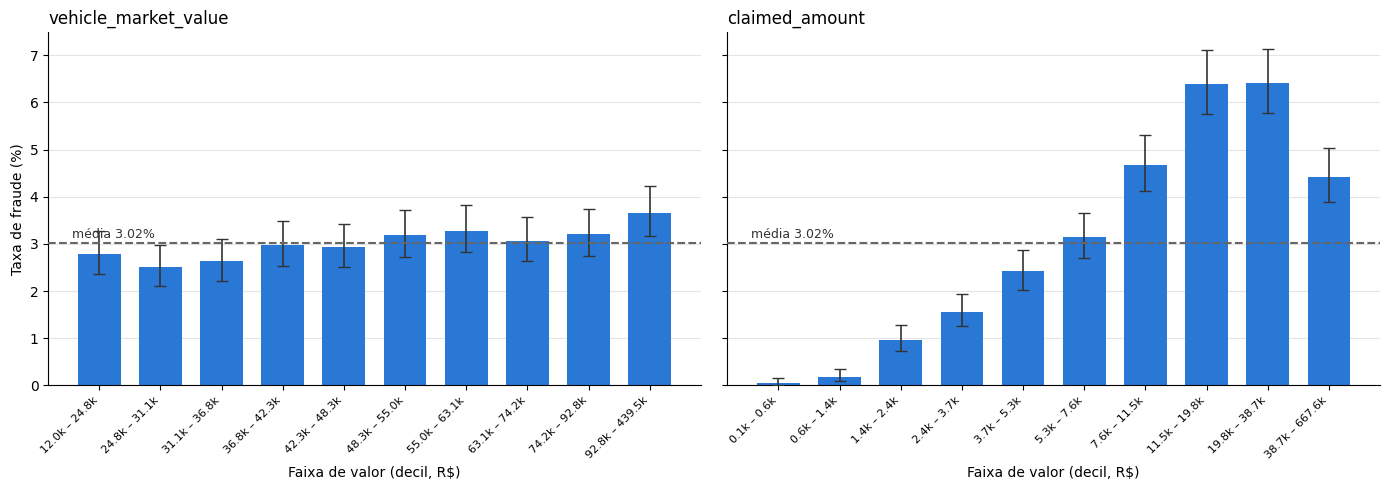

In [56]:
%matplotlib inline

def plot_taxa_por_faixa(tabelas: dict, taxa_base: float):
    '''tabelas: {título do painel: tabela de taxa_por_faixa_quantil}. Barra de erro = IC 95% (Wilson).'''
    base_pct = taxa_base * 100
    fig, axes = plt.subplots(1, len(tabelas), figsize=(7 * len(tabelas), 5), sharey=True)
    for ax, (titulo, t) in zip(np.atleast_1d(axes), tabelas.items()):
        x, taxa = np.arange(len(t)), t['taxa_%'].to_numpy()
        yerr = np.vstack([taxa - t['ic95_inf_%'].to_numpy(), t['ic95_sup_%'].to_numpy() - taxa])
        ax.bar(x, taxa, width=0.7, color='#2a78d6', zorder=2)
        ax.errorbar(x, taxa, yerr=yerr, fmt='none', ecolor='#333333', elinewidth=1.2, capsize=4, zorder=3)
        ax.axhline(base_pct, color='#666666', linestyle='--', linewidth=1.5, zorder=4)
        ax.text(-0.45, base_pct + 0.1, f'média {base_pct:.2f}%', fontsize=9, color='#333333')
        ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=45, ha='right', fontsize=8)
        ax.set_title(titulo, fontsize=12, loc='left'); ax.set_xlabel('Faixa de valor (decil, R$)')
        ax.grid(axis='y', color='#e5e5e5', zorder=0); ax.spines[['top', 'right']].set_visible(False)
    np.atleast_1d(axes)[0].set_ylabel('Taxa de fraude (%)')
    fig.tight_layout(); plt.show()

plot_taxa_por_faixa({'vehicle_market_value': tab_mercado, 'claimed_amount': tab_pedido}, df_estudo[COLUNA_ALVO].mean())

In [57]:
# Faixas de valor pedido em torno do corte da política atual (R$ 45 mil)
faixas_valor = [-1, 10000, 20000, 30000, 40000, CORTE_POLITICA_ATUAL, 60000, float('inf')]
nomes_valor = ['até 10 mil', '10 a 20 mil', '20 a 30 mil', '30 a 40 mil', '40 a 45 mil', '45 a 60 mil', 'acima de 60 mil']
tabela_valor = df_estudo.groupby(pd.cut(df_estudo['claimed_amount'], bins=faixas_valor, labels=nomes_valor),
                                 observed=False)[COLUNA_ALVO].agg(qtd='count', fraudes='sum')
tabela_valor['taxa_fraude_%'] = (tabela_valor['fraudes'] / tabela_valor['qtd'] * 100).round(2)
tabela_valor['pct_da_base_%'] = (tabela_valor['qtd'] / tabela_valor['qtd'].sum() * 100).round(2)
tabela_valor['pct_das_fraudes_%'] = (tabela_valor['fraudes'] / tabela_valor['fraudes'].sum() * 100).round(2)
print(tabela_valor)

                   qtd  fraudes  taxa_fraude_%  pct_da_base_%  pct_das_fraudes_%
claimed_amount                                                                  
até 10 mil       33395      562           1.68          66.79              37.19
10 a 20 mil       6689      411           6.14          13.38              27.20
20 a 30 mil       3040      207           6.81           6.08              13.70
30 a 40 mil       2114      122           5.77           4.23               8.07
40 a 45 mil        824       42           5.10           1.65               2.78
45 a 60 mil       1774       86           4.85           3.55               5.69
acima de 60 mil   2164       81           3.74           4.33               5.36


In [58]:
# Volume, fraude e sinistros acima do corte por mês do aviso, comparados com a capacidade de perícia
tabela_mes = df_estudo.groupby(df_estudo['report_date'].dt.to_period('M')).agg(
    qtd=(COLUNA_ALVO, 'count'), fraudes=(COLUNA_ALVO, 'sum'), taxa_fraude_pct=(COLUNA_ALVO, 'mean'),
    acima_do_corte=('claimed_amount', lambda s: int((s > CORTE_POLITICA_ATUAL).sum())))
tabela_mes['taxa_fraude_pct'] = (tabela_mes['taxa_fraude_pct'] * 100).round(2)
tabela_mes['capacidade_vs_avisos_%'] = (CAPACIDADE_PERICIA_MES / tabela_mes['qtd'] * 100).round(1)
tabela_mes['acima_do_corte_vs_capacidade_%'] = (tabela_mes['acima_do_corte'] / CAPACIDADE_PERICIA_MES * 100).round(1)
print(tabela_mes.to_string())
# Avisos de jan/2026 são eventos de dez/2025 avisados depois: mês incompleto, fica fora do treino e do teste.

              qtd  fraudes  taxa_fraude_pct  acima_do_corte  capacidade_vs_avisos_%  acima_do_corte_vs_capacidade_%
report_date                                                                                                        
2025-01      4758      118             2.48             389                    20.2                            40.5
2025-02      4415      149             3.37             330                    21.7                            34.4
2025-03      4691      150             3.20             369                    20.5                            38.4
2025-04      4136      134             3.24             344                    23.2                            35.8
2025-05      4077       99             2.43             346                    23.5                            36.0
2025-06      3706      113             3.05             280                    25.9                            29.2
2025-07      3634       95             2.61             282             

### Resultado da Fase 2 (decisões para a preparação dos dados)
- `paid_amount` sai da base: é definido depois da perícia e **vaza o alvo**.
- Separação **temporal** pela data do aviso: treino jan–nov/2025, teste dez/2025. Avisos de jan/2026 (mês incompleto) ficam de fora.
- `claim_id` sai: é só um identificador.
- `incident_date` e `report_date` viram `atraso_aviso` (dias entre a ocorrência e o aviso).
- `incident_time` vira apenas a hora (0 a 23).
- `report_channel`, `claim_type`, `third_party_identified` (e `state`, só na versão COM sensíveis) entram via one-hot.
- `prior_claims_12m` e `vehicle_market_value` entram como estão.
- `policyholder_age` e `state`: retiradas do modelo final (variáveis sensíveis; a Fase 4 compara com e sem elas).
- `vehicle_age` e `policy_tenure_days`: flags para os tetos de 25 anos e 5000 dias.
- `claimed_amount`: texto -> float.
- `police_report`: vazio -> `no` + flag `flag_police_report_nao_informado`.
- `is_fraud` é o alvo e não entra como variável.

## Preparação dos Dados [Fase 3 - CRISP-DM]
*Parâmetro `remover_sensiveis`: a versão final do modelo usa `remover_sensiveis=True`.*

In [59]:
COLUNAS_ONE_HOT = ['report_channel', 'claim_type', 'third_party_identified']
COLUNAS_SENSIVEIS = ['policyholder_age', 'state']          # risco LGPD / discriminação

COLUNAS_REMOVIDAS = ['paid_amount',     # vazamento: só existe depois da decisão
                     'claim_id',        # identificador, sem informação
                     'incident_date',   # usada só para derivar atraso_aviso
                     'report_date',     # usada só para derivar atraso_aviso (e para o split)
                     'incident_time']   # substituída pela hora numérica

COLUNAS_BRUTAS_OBRIGATORIAS = ['incident_date', 'incident_time', 'report_date', 'report_channel',
                               'claim_type', 'policy_tenure_days', 'prior_claims_12m', 'vehicle_age',
                               'vehicle_market_value', 'claimed_amount', 'police_report', 'third_party_identified']


def preparar_dados(df_bruto: pd.DataFrame, colunas_referencia: list | None = None, remover_sensiveis: bool = True):
    '''
    Aplica os tratamentos da Fase 3 a uma base BRUTA (layout do auto_claims.csv).

    colunas_referencia : None -> modo treino (aprende as categorias do one-hot nesta base)
                         lista -> modo teste/produção (alinha a saída às colunas do treino)
    remover_sensiveis  : True -> retira policyholder_age e state (versão final do modelo)
    Retorna: X tratado, y (ou None se não houver alvo) e a lista de colunas de X.
    '''
    df = df_bruto.copy()

    obrigatorias = COLUNAS_BRUTAS_OBRIGATORIAS + ([] if remover_sensiveis else COLUNAS_SENSIVEIS)
    faltando = [c for c in obrigatorias if c not in df.columns]
    if faltando:
        raise ValueError(f'preparar_dados espera a base BRUTA. Colunas ausentes: {faltando}.')
    valores_boletim = set(df['police_report'].dropna().unique())
    if not valores_boletim <= {'yes', 'no'}:
        raise ValueError(f'police_report deve ser "yes", "no" ou vazio. Recebido: {sorted(map(str, valores_boletim))}')

    y = df.pop(COLUNA_ALVO).astype(int) if COLUNA_ALVO in df.columns else None

    # atraso_aviso = dias entre a ocorrência e o aviso
    data_ocorrencia = pd.to_datetime(df['incident_date'], format='%Y-%m-%d', errors='coerce')
    data_aviso = pd.to_datetime(df['report_date'], format='%Y-%m-%d', errors='coerce')
    df['atraso_aviso'] = (data_aviso - data_ocorrencia).dt.days

    # incident_time (HH:MM) -> hora (0 a 23)
    df['hora'] = pd.to_datetime(df['incident_time'], format='%H:%M', errors='coerce').dt.hour

    # claimed_amount: texto BR -> float, OBRIGATÓRIO (> 0), não é imputado
    df['claimed_amount'] = converter_valor_br(df['claimed_amount'])
    invalido = df['claimed_amount'].isna() | (df['claimed_amount'] <= 0)
    if invalido.any():
        raise ValueError(f'claimed_amount ausente, não numérico ou <= 0 em {invalido.sum()} sinistro(s).')

    # Flags dos tetos
    df['flag_vehicle_age_25_anos'] = (df['vehicle_age'] >= 25).astype(int)
    df['flag_policy_tenure_5000'] = (df['policy_tenure_days'] >= 5000).astype(int)

    # police_report: flag de "não informado" ANTES de preencher; vazio -> "no"; 1 = yes, 0 = no
    df['flag_police_report_nao_informado'] = df['police_report'].isna().astype(int)
    df['police_report'] = (df['police_report'].fillna('no').str.strip() == 'yes').astype(int)

    remover = COLUNAS_REMOVIDAS + (COLUNAS_SENSIVEIS if remover_sensiveis else [])
    df = df.drop(columns=[c for c in remover if c in df.columns])

    colunas_one_hot = COLUNAS_ONE_HOT + ([] if remover_sensiveis else ['state'])
    df = pd.get_dummies(df, columns=colunas_one_hot, prefix=colunas_one_hot, dtype=int)

    if colunas_referencia is not None:
        df = df.reindex(columns=colunas_referencia, fill_value=0)

    return df, y, list(df.columns)


class PreparadorDados(BaseEstimator, TransformerMixin):
    '''preparar_dados() no padrão do scikit-learn (Pipeline / joblib).'''

    def __init__(self, remover_sensiveis: bool = True):
        self.remover_sensiveis = remover_sensiveis

    def fit(self, X, y=None):
        _, _, self.colunas_modelo_ = preparar_dados(X, remover_sensiveis=self.remover_sensiveis)
        return self

    def transform(self, X):
        check_is_fitted(self, 'colunas_modelo_')
        X_tratado, _, _ = preparar_dados(X, colunas_referencia=self.colunas_modelo_,
                                         remover_sensiveis=self.remover_sensiveis)
        return X_tratado

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, 'colunas_modelo_')
        return np.array(self.colunas_modelo_, dtype=object)

In [60]:
# Separação TEMPORAL pela data do aviso: treino = jan-nov/2025, teste = dez/2025
data_aviso_dt = pd.to_datetime(df['report_date'], format='%Y-%m-%d')
filtro_treino = data_aviso_dt.between(INICIO_TREINO, FIM_TREINO)
filtro_teste = data_aviso_dt.between(INICIO_TESTE, FIM_TESTE)
fora_do_periodo = ~(filtro_treino | filtro_teste)
df_treino = df[filtro_treino].copy()
df_teste = df[filtro_teste].copy()

# Conferências: só os avisos de jan/2026 (mês incompleto) ficam de fora, e nenhuma linha está nos dois períodos
assert not (filtro_treino & filtro_teste).any(), 'há linhas nos dois períodos'
assert (data_aviso_dt[fora_do_periodo] > FIM_TESTE).all(), 'há linhas fora do período que não são posteriores ao teste'
print(f"Treino: {len(df_treino):,} linhas ({len(df_treino)/len(df):.2%}) | fraude {df_treino[COLUNA_ALVO].mean():.2%}")
print(f"Teste : {len(df_teste):,} linhas ({len(df_teste)/len(df):.2%}) | fraude {df_teste[COLUNA_ALVO].mean():.2%}")
print(f"Fora  : {fora_do_periodo.sum():,} avisos posteriores a {FIM_TESTE} (mês incompleto)")

# Custo de uma fraude paga sem perícia = valor médio pedido nas fraudes do TREINO (arredondado em R$ 100)
CUSTO_FN = int(round(converter_valor_br(df_treino.loc[df_treino[COLUNA_ALVO] == 1, 'claimed_amount']).mean(), -2))
print(f'\nCUSTO_FN = R$ {CUSTO_FN:,} por fraude paga | CUSTO_PERICIA = R$ {CUSTO_PERICIA} '
      f'| relação {CUSTO_FN / CUSTO_PERICIA:.0f}:1'.replace(',', '.'))


def separar_x_y(df_base: pd.DataFrame):
    '''Base BRUTA (sem o alvo) e alvo. O preparo acontece DENTRO do pipeline.'''
    return df_base.drop(columns=[COLUNA_ALVO]), df_base[COLUNA_ALVO]


X_treino_bruto, y_treino = separar_x_y(df_treino)
X_teste_bruto, y_teste = separar_x_y(df_teste)

Treino: 45,138 linhas (90.28%) | fraude 2.98%
Teste : 4,719 linhas (9.44%) | fraude 3.31%
Fora  : 143 avisos posteriores a 2025-12-31 (mês incompleto)

CUSTO_FN = R$ 20.600 por fraude paga | CUSTO_PERICIA = R$ 700 | relação 29:1


In [61]:
# Conferência dos tratamentos (base final SEM sensíveis)
X_treino_conferencia = PreparadorDados(remover_sensiveis=True).fit_transform(X_treino_bruto)
print('Colunas após o preparo:', X_treino_conferencia.shape[1])
display(X_treino_conferencia.head(5))
X_treino_conferencia.info()

Colunas após o preparo: 23


,policy_tenure_days,prior_claims_12m,vehicle_age,vehicle_market_value,claimed_amount,police_report,atraso_aviso,hora,flag_vehicle_age_25_anos,flag_policy_tenure_5000,flag_police_report_nao_informado,report_channel_app,report_channel_broker,report_channel_call_center,claim_type_collision,claim_type_fire,claim_type_flood,claim_type_glass,claim_type_theft,claim_type_third_party_liability,third_party_identified_no,third_party_identified_not_applicable,third_party_identified_yes
0,1562,1,9,36700.0,4366.13,1,2,19,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0
1,1240,0,10,40300.0,1557.12,0,4,18,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0
2,2820,0,4,45700.0,80.00,1,2,12,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0
3,45,1,2,34500.0,1721.70,0,3,12,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0
4,1664,0,3,56200.0,55332.03,1,1,13,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0


<class 'pandas.core.frame.DataFrame'>
Index: 45138 entries, 0 to 49999
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   policy_tenure_days                     45138 non-null  int64  
 1   prior_claims_12m                       45138 non-null  int64  
 2   vehicle_age                            45138 non-null  int64  
 3   vehicle_market_value                   45138 non-null  float64
 4   claimed_amount                         45138 non-null  float64
 5   police_report                          45138 non-null  int64  
 6   atraso_aviso                           45138 non-null  int64  
 7   hora                                   45138 non-null  int32  
 8   flag_vehicle_age_25_anos               45138 non-null  int64  
 9   flag_policy_tenure_5000                45138 non-null  int64  
 10  flag_police_report_nao_informado       45138 non-null  int64  
 11  report_

## Modelagem [Fase 4 - CRISP-DM]
### Pipeline, validação cruzada e métricas

In [62]:
def criar_pipeline(modelo='passthrough', remover_sensiveis: bool = True) -> Pipeline:
    '''Preparo -> Imputação (mediana do treino) -> Modelo. Saída em DataFrame para o SHAP nomear as features.'''
    pipeline = Pipeline(steps=[
        ('preparo', PreparadorDados(remover_sensiveis=remover_sensiveis)),
        ('imputacao', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('modelo', modelo),
    ])
    pipeline.set_output(transform='pandas')
    return pipeline


def transformar_para_modelo(pipeline: Pipeline, X_bruto: pd.DataFrame) -> pd.DataFrame:
    '''Preparo + Imputação de um pipeline JÁ AJUSTADO: a base exatamente como o modelo vê (entrada do SHAP).'''
    return pipeline[:-1].transform(X_bruto)


def feature_original(coluna: str) -> str:
    '''claim_type_collision -> claim_type (para somar o SHAP das colunas one-hot por variável de negócio).'''
    for prefixo in COLUNAS_ONE_HOT + ['state']:
        if coluna.startswith(prefixo + '_'):
            return prefixo
    return coluna


cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas_avaliacao = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'acuracia': 'accuracy'}

### Hiperparâmetros da Árvore (max_depth) e da Random Forest (min_samples_leaf), base SEM sensíveis

In [63]:
def tabela_hiperparametro(fabrica_modelo, valores, rotulo: str, remover_sensiveis: bool = True) -> pd.DataFrame:
    '''Média da validação cruzada (treino) para cada valor de um hiperparâmetro.'''
    linhas = []
    for v in valores:
        res = cross_validate(criar_pipeline(fabrica_modelo(v), remover_sensiveis), X_treino_bruto, y_treino,
                             cv=cv_estratificado, scoring=metricas_avaliacao, n_jobs=-1)
        linhas.append({rotulo: v, 'ROC AUC': round(res['test_roc_auc'].mean(), 4),
                       'PR AUC': round(res['test_pr_auc'].mean(), 4),
                       'Acurácia': round(res['test_acuracia'].mean(), 4)})
    return pd.DataFrame(linhas)


tabela_arvore = tabela_hiperparametro(lambda d: DecisionTreeClassifier(max_depth=d, random_state=SEED),
                                      range(1, 11), 'max_depth')
print(tabela_arvore.to_string(index=False))
MAX_DEPTH_ARVORE = int(tabela_arvore.loc[tabela_arvore['ROC AUC'].idxmax(), 'max_depth'])
print(f'\nmax_depth escolhido (maior ROC AUC na validação cruzada): {MAX_DEPTH_ARVORE}')

 max_depth  ROC AUC  PR AUC  Acurácia
         1   0.6931  0.0494    0.9702
         2   0.7540  0.0784    0.9701
         3   0.7744  0.1057    0.9700
         4   0.7996  0.1353    0.9706
         5   0.8128  0.1461    0.9703
         6   0.8165  0.1448    0.9696
         7   0.8195  0.1487    0.9686
         8   0.8159  0.1530    0.9685
         9   0.7983  0.1435    0.9672
        10   0.7756  0.1346    0.9657

max_depth escolhido (maior ROC AUC na validação cruzada): 7


In [64]:
tabela_rf = tabela_hiperparametro(lambda f: RandomForestClassifier(min_samples_leaf=f, class_weight='balanced',
                                                                   random_state=SEED, n_jobs=1),
                                  [1, 5, 10, 20, 50, 100, 200], 'min_samples_leaf')
print(tabela_rf.to_string(index=False))
MIN_SAMPLES_LEAF_RF = int(tabela_rf.loc[tabela_rf['ROC AUC'].idxmax(), 'min_samples_leaf'])
print(f'\nmin_samples_leaf escolhido (maior ROC AUC na validação cruzada): {MIN_SAMPLES_LEAF_RF}')

 min_samples_leaf  ROC AUC  PR AUC  Acurácia
                1   0.8297  0.1856    0.9703
                5   0.8626  0.2151    0.9544
               10   0.8646  0.2277    0.9234
               20   0.8650  0.2256    0.8799
               50   0.8649  0.2273    0.8238
              100   0.8646  0.2214    0.7894
              200   0.8630  0.2122    0.7642

min_samples_leaf escolhido (maior ROC AUC na validação cruzada): 20


### Modelos e otimização de XGBoost / LightGBM

In [65]:
def modelo_dummy(remover_sensiveis=True):
    return criar_pipeline(DummyClassifier(strategy='prior'), remover_sensiveis)


def modelo_arvore(remover_sensiveis=True):
    return criar_pipeline(DecisionTreeClassifier(max_depth=MAX_DEPTH_ARVORE, random_state=SEED), remover_sensiveis)


def modelo_random_forest(remover_sensiveis=True):
    return criar_pipeline(RandomForestClassifier(min_samples_leaf=MIN_SAMPLES_LEAF_RF, class_weight='balanced',
                                                 random_state=SEED, n_jobs=1), remover_sensiveis)


def otimizar_xgboost(X, y, remover_sensiveis=True):
    '''GridSearch do XGBoost (ROC AUC, StratifiedKFold 5), SEMPRE na base de treino.'''
    taxa_desbalanceamento = (y == 0).sum() / (y == 1).sum()
    grid = GridSearchCV(
        criar_pipeline(xgb.XGBClassifier(random_state=SEED, eval_metric='logloss',
                                         scale_pos_weight=taxa_desbalanceamento, n_jobs=1), remover_sensiveis),
        param_grid={'modelo__max_depth': [3, 5, 7],
                    'modelo__learning_rate': [0.03, 0.1],
                    'modelo__n_estimators': [100, 300],
                    'modelo__min_child_weight': [1, 5, 20]},
        cv=cv_estratificado, scoring='roc_auc', n_jobs=-1)
    grid.fit(X, y)
    print(f'Melhores parâmetros XGBoost ({"sem" if remover_sensiveis else "com"} sensíveis): {grid.best_params_}')
    return grid.best_estimator_


def otimizar_lightgbm(X, y, remover_sensiveis=True):
    '''GridSearch do LightGBM (ROC AUC, StratifiedKFold 5), SEMPRE na base de treino.'''
    taxa_desbalanceamento = (y == 0).sum() / (y == 1).sum()
    grid = GridSearchCV(
        criar_pipeline(lgb.LGBMClassifier(random_state=SEED, scale_pos_weight=taxa_desbalanceamento,
                                          max_depth=-1, verbose=-1, n_jobs=1), remover_sensiveis),
        param_grid={'modelo__num_leaves': [7, 15, 31, 63],
                    'modelo__learning_rate': [0.03, 0.1],
                    'modelo__n_estimators': [100, 300],
                    'modelo__min_child_samples': [20, 50, 100]},
        cv=cv_estratificado, scoring='roc_auc', n_jobs=-1)
    grid.fit(X, y)
    print(f'Melhores parâmetros LightGBM ({"sem" if remover_sensiveis else "com"} sensíveis): {grid.best_params_}')
    return grid.best_estimator_


def montar_modelos(remover_sensiveis=True) -> dict:
    '''Os 5 modelos do projeto (XGBoost e LightGBM já otimizados no treino).'''
    return {'1. Dummy (Prior)': modelo_dummy(remover_sensiveis),
            '2. Árvore de Decisão': modelo_arvore(remover_sensiveis),
            '3. Random Forest (balanced)': modelo_random_forest(remover_sensiveis),
            '4. XGBoost (Otimizado)': otimizar_xgboost(X_treino_bruto, y_treino, remover_sensiveis),
            '5. LightGBM (Otimizado)': otimizar_lightgbm(X_treino_bruto, y_treino, remover_sensiveis)}


def avaliar_modelos_cv(modelos: dict) -> pd.DataFrame:
    '''Validação cruzada no TREINO: média e desvio de cada métrica.'''
    linhas = []
    for nome, pipe in modelos.items():
        res = cross_validate(pipe, X_treino_bruto, y_treino, cv=cv_estratificado,
                             scoring=metricas_avaliacao, n_jobs=-1)
        linha = {'Modelo': nome}
        for m in metricas_avaliacao:
            linha[f'{m} (Média)'] = res[f'test_{m}'].mean()
            linha[f'{m} (Desvio)'] = res[f'test_{m}'].std()
        linhas.append(linha)
    return pd.DataFrame(linhas).sort_values('roc_auc (Média)', ascending=False).reset_index(drop=True)


def comparar_resultados(df_com: pd.DataFrame, df_sem: pd.DataFrame) -> pd.DataFrame:
    '''Uma linha por modelo x métrica, COM x SEM idade/UF e a diferença.'''
    metricas = {'roc_auc (Média)': 'ROC AUC', 'pr_auc (Média)': 'PR AUC', 'acuracia (Média)': 'Acurácia'}
    linhas = []
    for _, lin_com in df_com.iterrows():
        lin_sem = df_sem[df_sem['Modelo'] == lin_com['Modelo']].iloc[0]
        for coluna, nome in metricas.items():
            linhas.append({'Modelo': lin_com['Modelo'], 'Métrica': nome,
                           'COM idade/UF': round(lin_com[coluna], 4),
                           'SEM idade/UF': round(lin_sem[coluna], 4),
                           'Diferença (SEM − COM)': round(lin_sem[coluna] - lin_com[coluna], 4)})
    return pd.DataFrame(linhas).sort_values('Modelo', kind='stable').reset_index(drop=True)

In [66]:
modelos_com = montar_modelos(remover_sensiveis=False)
modelos_sem = montar_modelos(remover_sensiveis=True)

df_comparativo = avaliar_modelos_cv(modelos_com)
df_comparativo_sem_sensiveis = avaliar_modelos_cv(modelos_sem)
print('\nValidação cruzada (treino), SEM sensíveis:')
print(df_comparativo_sem_sensiveis.round(4).to_string(index=False))

Melhores parâmetros XGBoost (com sensíveis): {'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__min_child_weight': 5, 'modelo__n_estimators': 100}
Melhores parâmetros LightGBM (com sensíveis): {'modelo__learning_rate': 0.03, 'modelo__min_child_samples': 50, 'modelo__n_estimators': 300, 'modelo__num_leaves': 7}
Melhores parâmetros XGBoost (sem sensíveis): {'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__min_child_weight': 1, 'modelo__n_estimators': 100}
Melhores parâmetros LightGBM (sem sensíveis): {'modelo__learning_rate': 0.03, 'modelo__min_child_samples': 20, 'modelo__n_estimators': 300, 'modelo__num_leaves': 7}

Validação cruzada (treino), SEM sensíveis:
                     Modelo  roc_auc (Média)  roc_auc (Desvio)  pr_auc (Média)  pr_auc (Desvio)  acuracia (Média)  acuracia (Desvio)
     4. XGBoost (Otimizado)           0.8733            0.0046          0.2599           0.0180            0.7862             0.0069
    5. LightGBM (Otimizado)           0.

In [67]:
comparacao_treino = comparar_resultados(df_comparativo, df_comparativo_sem_sensiveis)
print(comparacao_treino.to_string(index=False))

                     Modelo  Métrica  COM idade/UF  SEM idade/UF  Diferença (SEM − COM)
           1. Dummy (Prior)  ROC AUC        0.5000        0.5000                 0.0000
           1. Dummy (Prior)   PR AUC        0.0298        0.0298                 0.0000
           1. Dummy (Prior) Acurácia        0.9702        0.9702                 0.0000
       2. Árvore de Decisão  ROC AUC        0.8163        0.8195                 0.0031
       2. Árvore de Decisão   PR AUC        0.1492        0.1487                -0.0005
       2. Árvore de Decisão Acurácia        0.9690        0.9686                -0.0004
3. Random Forest (balanced)  ROC AUC        0.8643        0.8650                 0.0006
3. Random Forest (balanced)   PR AUC        0.2199        0.2256                 0.0057
3. Random Forest (balanced) Acurácia        0.8756        0.8799                 0.0043
     4. XGBoost (Otimizado)  ROC AUC        0.8717        0.8733                 0.0016
     4. XGBoost (Otimizado)   PR

## Avaliação no teste [Fase 5 - CRISP-DM]: dezembro/2025, dados nunca vistos

In [68]:
def avaliar_no_teste(modelos: dict) -> tuple[pd.DataFrame, dict]:
    '''Ajusta cada pipeline no TREINO completo e mede ROC AUC, PR AUC e Acurácia no TESTE.'''
    linhas, ajustados = [], {}
    for nome, pipe in modelos.items():
        modelo = clone(pipe).fit(X_treino_bruto, y_treino)
        proba = modelo.predict_proba(X_teste_bruto)[:, 1]
        ajustados[nome] = modelo
        linhas.append({'Modelo': nome,
                       'roc_auc (Média)': roc_auc_score(y_teste, proba),
                       'pr_auc (Média)': average_precision_score(y_teste, proba),
                       'acuracia (Média)': accuracy_score(y_teste, (proba >= 0.5).astype(int))})
    tabela = pd.DataFrame(linhas).sort_values('roc_auc (Média)', ascending=False).reset_index(drop=True)
    return tabela, ajustados


df_teste_comparativo, ajustados_com = avaliar_no_teste(modelos_com)
df_teste_comparativo_sem_sensiveis, ajustados_sem = avaliar_no_teste(modelos_sem)
print('Teste (dezembro), SEM sensíveis:')
print(df_teste_comparativo_sem_sensiveis.round(4).to_string(index=False))

Teste (dezembro), SEM sensíveis:
                     Modelo  roc_auc (Média)  pr_auc (Média)  acuracia (Média)
    5. LightGBM (Otimizado)           0.8695          0.2633            0.7733
     4. XGBoost (Otimizado)           0.8655          0.2599            0.7743
3. Random Forest (balanced)           0.8641          0.2514            0.8718
       2. Árvore de Decisão           0.8461          0.2029            0.9672
           1. Dummy (Prior)           0.5000          0.0331            0.9669


In [69]:
comparacao_teste = comparar_resultados(df_teste_comparativo, df_teste_comparativo_sem_sensiveis)
print(comparacao_teste.to_string(index=False))

                     Modelo  Métrica  COM idade/UF  SEM idade/UF  Diferença (SEM − COM)
           1. Dummy (Prior)  ROC AUC        0.5000        0.5000                 0.0000
           1. Dummy (Prior)   PR AUC        0.0331        0.0331                 0.0000
           1. Dummy (Prior) Acurácia        0.9669        0.9669                 0.0000
       2. Árvore de Decisão  ROC AUC        0.8475        0.8461                -0.0013
       2. Árvore de Decisão   PR AUC        0.1949        0.2029                 0.0080
       2. Árvore de Decisão Acurácia        0.9667        0.9672                 0.0004
3. Random Forest (balanced)  ROC AUC        0.8663        0.8641                -0.0022
3. Random Forest (balanced)   PR AUC        0.2452        0.2514                 0.0061
3. Random Forest (balanced) Acurácia        0.8684        0.8718                 0.0034
     4. XGBoost (Otimizado)  ROC AUC        0.8655        0.8655                 0.0000
     4. XGBoost (Otimizado)   PR

## Projeção de custos: base de TESTE (dezembro/2025), modelos SEM dados sensíveis
**Custo = FN × CUSTO_FN + nº de perícias × R\$ 700** (toda perícia custa R\$ 700, encontrando fraude ou não), para cada limiar de 0,01 a 0,99.

A capacidade de 960 perícias/mês **não restringe a escolha do modelo**: a empresa pode contratar peritos se a economia compensar. Para cada modelo mostramos:
- o **limiar de menor custo** e quantos **peritos** ele exige (1 perito = 30 perícias/mês);
- a **economia de cada perito adicional** (a partir dos 32 atuais);
- a **política atual** (valor > R\$ 45 mil, maior → menor, até 960) como referência.

*Cuidado: o limiar é escolhido no próprio teste, então o custo mínimo é uma estimativa otimista.*

In [70]:
LIMIARES = np.round(np.arange(0.01, 1.00, 0.01), 2)


def custo_total(y_true, probabilidades, limiar, custo_fn=None, custo_pericia=CUSTO_PERICIA):
    '''Custo para um limiar: FN x custo_fn + (nº de perícias) x custo_pericia. Devolve (custo, FN, FP, VP).'''
    custo_fn = CUSTO_FN if custo_fn is None else custo_fn
    y_true = np.asarray(y_true)
    sinaliza = np.asarray(probabilidades) >= limiar
    fn = int(((y_true == 1) & ~sinaliza).sum())
    fp = int(((y_true == 0) & sinaliza).sum())
    vp = int(((y_true == 1) & sinaliza).sum())
    return fn * custo_fn + (vp + fp) * custo_pericia, fn, fp, vp


def curva_custo(y_true, probabilidades, custo_fn=None, custo_pericia=CUSTO_PERICIA) -> pd.DataFrame:
    '''Custo, FN, FP, VP e nº de perícias para cada limiar de 0,01 a 0,99.'''
    linhas = []
    for limiar in LIMIARES:
        custo, fn, fp, vp = custo_total(y_true, probabilidades, limiar, custo_fn, custo_pericia)
        linhas.append({'limiar': limiar, 'custo': custo, 'FN': fn, 'FP': fp, 'VP': vp, 'pericias': vp + fp})
    return pd.DataFrame(linhas)


def custo_da_selecao(y_true, selecionados, custo_fn=None, custo_pericia=CUSTO_PERICIA) -> dict:
    '''Custo de uma lista de sinistros periciados (máscara booleana).'''
    custo_fn = CUSTO_FN if custo_fn is None else custo_fn
    y_true, sel = np.asarray(y_true), np.asarray(selecionados)
    fn = int(((y_true == 1) & ~sel).sum()); fp = int(((y_true == 0) & sel).sum()); vp = int(((y_true == 1) & sel).sum())
    return {'Custo total (R$)': fn * custo_fn + int(sel.sum()) * custo_pericia, 'FN': fn, 'FP': fp, 'VP': vp,
            'Fraudes detectadas (%)': round((1 - fn / y_true.sum()) * 100, 1), 'Perícias': int(sel.sum())}


def tabela_menor_custo(probas_por_modelo: dict, y_true, n_meses: int) -> pd.DataFrame:
    '''Para cada modelo: limiar de menor custo e os números dessa decisão, mais as referências.'''
    y_true = np.asarray(y_true)
    linhas = []
    for nome, proba in probas_por_modelo.items():
        curva = curva_custo(y_true, proba)
        melhor = curva.loc[curva['custo'].idxmin()]
        linhas.append({'Modelo': nome, 'Limiar de menor custo': melhor['limiar'],
                       'Custo total (R$)': int(melhor['custo']), 'FN': int(melhor['FN']), 'FP': int(melhor['FP']),
                       'Fraudes encontradas (VP)': int(melhor['VP']),
                       'Fraudes detectadas (%)': round(melhor['VP'] / y_true.sum() * 100, 1),
                       'Perícias': int(melhor['pericias']),
                       'Perícias por mês': round(melhor['pericias'] / n_meses)})
    linhas.append({'Modelo': 'Referência: periciar ninguém', 'Limiar de menor custo': np.nan,
                   'Custo total (R$)': int(y_true.sum() * CUSTO_FN), 'FN': int(y_true.sum()), 'FP': 0,
                   'Fraudes encontradas (VP)': 0, 'Fraudes detectadas (%)': 0.0, 'Perícias': 0, 'Perícias por mês': 0})
    linhas.append({'Modelo': 'Referência: periciar todos', 'Limiar de menor custo': np.nan,
                   'Custo total (R$)': int(len(y_true) * CUSTO_PERICIA), 'FN': 0, 'FP': int((y_true == 0).sum()),
                   'Fraudes encontradas (VP)': int(y_true.sum()), 'Fraudes detectadas (%)': 100.0,
                   'Perícias': len(y_true), 'Perícias por mês': round(len(y_true) / n_meses)})
    return pd.DataFrame(linhas).sort_values('Custo total (R$)').reset_index(drop=True)


def selecao_top_k(probabilidades, k: int) -> np.ndarray:
    '''Máscara dos k sinistros de maior probabilidade (fila de perícia do modelo).'''
    selecionados = np.zeros(len(probabilidades), dtype=bool)
    selecionados[np.argsort(-np.asarray(probabilidades), kind='stable')[:k]] = True
    return selecionados

In [71]:
MODELOS_FINALISTAS = ['3. Random Forest (balanced)', '4. XGBoost (Otimizado)', '5. LightGBM (Otimizado)']
probas_teste = {nome: ajustados_sem[nome].predict_proba(X_teste_bruto)[:, 1] for nome in MODELOS_FINALISTAS}
n_meses_teste = df_teste['report_date'].str[:7].nunique()
print(f'Teste: {X_teste_bruto.shape} | fraudes: {y_teste.sum()} | meses: {n_meses_teste} | '
      f'CUSTO_FN={CUSTO_FN} | CUSTO_PERICIA={CUSTO_PERICIA}')

# 1) Limiar de menor custo (sem limite de capacidade)
tabela_custos_teste = tabela_menor_custo(probas_teste, y_teste, n_meses_teste)
print('\n1) Limiar de menor custo, sem limite de capacidade:')
print(tabela_custos_teste.to_string(index=False))

Teste: (4719, 16) | fraudes: 156 | meses: 1 | CUSTO_FN=20600 | CUSTO_PERICIA=700

1) Limiar de menor custo, sem limite de capacidade:
                      Modelo  Limiar de menor custo  Custo total (R$)  FN   FP  Fraudes encontradas (VP)  Fraudes detectadas (%)  Perícias  Perícias por mês
     5. LightGBM (Otimizado)                   0.54           1438500  35  904                       121                    77.6      1025              1025
      4. XGBoost (Otimizado)                   0.49           1507900  33 1060                       123                    78.8      1183              1183
 3. Random Forest (balanced)                   0.22           1514600  11 1695                       145                    92.9      1840              1840
Referência: periciar ninguém                    NaN           3213600 156    0                         0                     0.0         0                 0
  Referência: periciar todos                    NaN           3303300   0 4563   

In [72]:
# 2) Política atual x modelos sem restrição de capacidade + peritos necessários
valor_pedido_teste = converter_valor_br(df_teste['claimed_amount']).to_numpy()
pericias_atuais = CAPACIDADE_PERICIA_MES * n_meses_teste

# Política atual: claimed_amount > R$ 45 mil, do maior para o menor, até a capacidade atual
candidatos = np.where(valor_pedido_teste > CORTE_POLITICA_ATUAL)[0]
sel_atual = np.zeros(len(y_teste), dtype=bool)
sel_atual[candidatos[np.argsort(-valor_pedido_teste[candidatos], kind='stable')][:pericias_atuais]] = True
politica_atual = custo_da_selecao(y_teste, sel_atual)
custo_atual = politica_atual['Custo total (R$)']
ociosas = pericias_atuais - politica_atual['Perícias']

tabela_sem_capacidade = tabela_custos_teste[tabela_custos_teste['Modelo'].isin(MODELOS_FINALISTAS)].copy()
tabela_sem_capacidade['Peritos necessários'] = np.ceil(
    tabela_sem_capacidade['Perícias por mês'] / PERICIAS_POR_PERITO_MES).astype(int)
tabela_sem_capacidade['Peritos vs equipe atual'] = tabela_sem_capacidade['Peritos necessários'] - PERITOS_ATUAIS
tabela_sem_capacidade['Economia vs política atual (R$)'] = custo_atual - tabela_sem_capacidade['Custo total (R$)']
tabela_sem_capacidade['Economia (%)'] = (tabela_sem_capacidade['Economia vs política atual (R$)'] / custo_atual * 100).round(1)

print(f'Política atual: {len(candidatos)} sinistros > R$ {CORTE_POLITICA_ATUAL:,.0f} no teste | '
      f'{politica_atual["Perícias"]} perícias de {pericias_atuais} possíveis ({ociosas} ociosas) | '
      f'fraudes detectadas {politica_atual["Fraudes detectadas (%)"]}% | custo R$ {custo_atual:,.0f}'.replace(',', '.'))
print('\nModelos no limiar de menor custo (sem limite de capacidade):')
print(tabela_sem_capacidade[['Modelo', 'Limiar de menor custo', 'Custo total (R$)', 'Fraudes detectadas (%)',
                             'Perícias por mês', 'Peritos necessários', 'Peritos vs equipe atual',
                             'Economia vs política atual (R$)', 'Economia (%)']].to_string(index=False))

Política atual: 356 sinistros > R$ 45.000 no teste | 356 perícias de 960 possíveis (604 ociosas) | fraudes detectadas 13.5% | custo R$ 3.030.200

Modelos no limiar de menor custo (sem limite de capacidade):
                     Modelo  Limiar de menor custo  Custo total (R$)  Fraudes detectadas (%)  Perícias por mês  Peritos necessários  Peritos vs equipe atual  Economia vs política atual (R$)  Economia (%)
    5. LightGBM (Otimizado)                   0.54           1438500                    77.6              1025                   35                        3                          1591700          52.5
     4. XGBoost (Otimizado)                   0.49           1507900                    78.8              1183                   40                        8                          1522300          50.2
3. Random Forest (balanced)                   0.22           1514600                    92.9              1840                   62                       30                         

In [73]:
# 2b) Quanto cada perito ADICIONAL economiza? (fila = maiores scores; 1 perito = 30 perícias/mês)
max_peritos = len(y_teste) // (PERICIAS_POR_PERITO_MES * n_meses_teste)
peritos_avaliados = list(range(PERITOS_ATUAIS, min(PERITOS_ATUAIS * 3, max_peritos) + 1))
linhas = []
for nome, proba in probas_teste.items():
    for p in peritos_avaliados:
        k = p * PERICIAS_POR_PERITO_MES * n_meses_teste
        linhas.append({'Modelo': nome, 'Peritos': p, 'Perícias': k,
                       **{c: v for c, v in custo_da_selecao(y_teste, selecao_top_k(proba, k)).items() if c != 'Perícias'}})
curva_peritos = pd.DataFrame(linhas)
curva_peritos['Economia do perito adicional (R$)'] = -curva_peritos.groupby('Modelo')['Custo total (R$)'].diff()

# Também avaliamos equipes MENORES que a atual (a equipe de 32 pode estar sobrando)
linhas_menores = []
for nome, proba in probas_teste.items():
    for p in range(1, PERITOS_ATUAIS):
        k = p * PERICIAS_POR_PERITO_MES * n_meses_teste
        linhas_menores.append({'Modelo': nome, 'Peritos': p,
                               'Custo total (R$)': custo_da_selecao(y_teste, selecao_top_k(proba, k))['Custo total (R$)']})
curva_completa = pd.concat([pd.DataFrame(linhas_menores), curva_peritos[['Modelo', 'Peritos', 'Custo total (R$)']]])

resumo = []
for nome, g in curva_completa.groupby('Modelo', sort=False):
    g = g.set_index('Peritos')
    p_otimo = int(g['Custo total (R$)'].idxmin())
    resumo.append({'Modelo': nome,
                   f'Custo c/ {PERITOS_ATUAIS} peritos (R$)': int(g.loc[PERITOS_ATUAIS, 'Custo total (R$)']),
                   f'Economia do {PERITOS_ATUAIS + 1}º perito (R$)': int(g.loc[PERITOS_ATUAIS, 'Custo total (R$)']
                                                                         - g.loc[PERITOS_ATUAIS + 1, 'Custo total (R$)']),
                   'Peritos de menor custo': p_otimo,
                   'Custo no nº ótimo de peritos (R$)': int(g.loc[p_otimo, 'Custo total (R$)'])})
resumo_peritos = pd.DataFrame(resumo)
print('Custo por tamanho de equipe (fila pelos maiores scores):')
print(resumo_peritos.to_string(index=False))

print('\nCusto (R$) por número de peritos:')
print(curva_completa[curva_completa['Peritos'] % 4 == 0].pivot(index='Peritos', columns='Modelo',
                                                                values='Custo total (R$)').to_string())

Custo por tamanho de equipe (fila pelos maiores scores):
                     Modelo  Custo c/ 32 peritos (R$)  Economia do 33º perito (R$)  Peritos de menor custo  Custo no nº ótimo de peritos (R$)
3. Random Forest (balanced)                   1578400                        20200                      62                            1508000
     4. XGBoost (Otimizado)                   1578400                         -400                      56                            1505600
    5. LightGBM (Otimizado)                   1537200                        40800                      35                            1435400

Custo (R$) por número de peritos:
Modelo   3. Random Forest (balanced)  4. XGBoost (Otimizado)  5. LightGBM (Otimizado)
Peritos                                                                              
4                            2350000                 2411800                  2411800
8                            2042600                 1980800                  2001

In [74]:
# 3) Estabilidade: custo nos limiares vizinhos ao ótimo
for nome, proba in probas_teste.items():
    curva = curva_custo(y_teste, proba); i = curva['custo'].idxmin()
    print(f'\n{nome}:')
    print(curva.iloc[max(i - 3, 0):i + 4][['limiar', 'custo', 'FN', 'FP', 'VP', 'pericias']].to_string(index=False))


3. Random Forest (balanced):
 limiar   custo  FN   FP  VP  pericias
   0.19 1636900   8 1955 148      2103
   0.20 1591000   9 1861 147      2008
   0.21 1542300  10 1763 146      1909
   0.22 1514600  11 1695 145      1840
   0.23 1557100  15 1642 141      1783
   0.24 1544400  17 1567 139      1706
   0.25 1586200  21 1513 135      1648

4. XGBoost (Otimizado):
 limiar   custo  FN   FP  VP  pericias
   0.46 1568500  32 1175 124      1299
   0.47 1533500  32 1125 124      1249
   0.48 1514600  32 1098 124      1222
   0.49 1507900  33 1060 123      1183
   0.50 1526700  35 1030 121      1151
   0.51 1542700  37  996 119      1115
   0.52 1558000  39  961 117      1078

5. LightGBM (Otimizado):
 limiar   custo  FN   FP  VP  pericias
   0.51 1490700  34 1007 122      1129
   0.52 1466900  34  973 122      1095
   0.53 1441000  34  936 122      1058
   0.54 1438500  35  904 121      1025
   0.55 1494300  39  870 117       987
   0.56 1534400  42  842 114       956
   0.57 1512000  42  8

## Decisão do modelo
**Critério:** menor custo total no teste **sem restrição de capacidade**. O modelo escolhido é calculado pelo código, não fixado à mão.

In [75]:
comparativo_final = (tabela_sem_capacidade[['Modelo', 'Limiar de menor custo', 'Custo total (R$)', 'Fraudes detectadas (%)',
                                            'Perícias por mês', 'Peritos necessários', 'Peritos vs equipe atual',
                                            'Economia vs política atual (R$)', 'Economia (%)']]
                     .merge(resumo_peritos[['Modelo', f'Custo c/ {PERITOS_ATUAIS} peritos (R$)']], on='Modelo')
                     .merge(df_teste_comparativo_sem_sensiveis[['Modelo', 'roc_auc (Média)', 'pr_auc (Média)']]
                            .rename(columns={'roc_auc (Média)': 'ROC AUC teste', 'pr_auc (Média)': 'PR AUC teste'}),
                            on='Modelo')
                     .sort_values('Custo total (R$)').reset_index(drop=True))
comparativo_final.insert(0, 'Posição', range(1, len(comparativo_final) + 1))

MODELO_ESCOLHIDO = comparativo_final.loc[0, 'Modelo']
LIMIAR_ESCOLHIDO = float(comparativo_final.loc[0, 'Limiar de menor custo'])
custo_escolhido = comparativo_final.loc[0, 'Custo total (R$)']

comparativo_final['Dif. vs escolhido (R$)'] = comparativo_final['Custo total (R$)'] - custo_escolhido
comparativo_final['Dif. vs escolhido (%)'] = (comparativo_final['Dif. vs escolhido (R$)'] / custo_escolhido * 100).round(1)
comparativo_final[['ROC AUC teste', 'PR AUC teste']] = comparativo_final[['ROC AUC teste', 'PR AUC teste']].round(4)
comparativo_final = comparativo_final.rename(columns={'Limiar de menor custo': 'Limiar',
                                                      'Custo total (R$)': 'Custo no limiar ótimo (R$)'})

print(f'Modelo escolhido (menor custo sem restrição de capacidade): {MODELO_ESCOLHIDO} | limiar {LIMIAR_ESCOLHIDO}')
print(f'Custo da política atual em dezembro: R$ {custo_atual:,.0f}'.replace(',', '.'))
display(comparativo_final.set_index('Posição').T)

Modelo escolhido (menor custo sem restrição de capacidade): 5. LightGBM (Otimizado) | limiar 0.54
Custo da política atual em dezembro: R$ 3.030.200


Posição,1,2,3
Modelo,5. LightGBM (Otimizado),4. XGBoost (Otimizado),3. Random Forest (balanced)
Limiar,0.54,0.49,0.22
Custo no limiar ótimo (R$),1438500,1507900,1514600
Fraudes detectadas (%),77.6,78.8,92.9
Perícias por mês,1025,1183,1840
Peritos necessários,35,40,62
Peritos vs equipe atual,3,8,30
Economia vs política atual (R$),1591700,1522300,1515600
Economia (%),52.5,50.2,50.0
Custo c/ 32 peritos (R$),1537200,1578400,1578400


## Vale a pena mudar o tamanho da equipe de perícia?
Usando a fila do modelo escolhido (sinistros ordenados pela probabilidade de fraude, teste de dezembro/2025):
- **acerto mínimo** que uma perícia a mais precisa ter para se pagar;
- **até quantas perícias por mês** compensa periciar;
- **hipótese:** com o dobro de peritos, a seguradora pegaria o dobro de fraudes?

In [76]:
proba = probas_teste[MODELO_ESCOLHIDO]
y = np.asarray(y_teste)
ordem = np.argsort(-proba, kind='stable')
fraude_na_fila = y[ordem]

# (a) Acerto mínimo: uma perícia a mais se paga quando  acerto x CUSTO_FN >= CUSTO_PERICIA
acerto_minimo = CUSTO_PERICIA / CUSTO_FN
print(f'(a) Acerto mínimo para uma perícia a mais se pagar: {acerto_minimo:.2%} '
      f'(1 fraude a cada {1/acerto_minimo:.0f} perícias)')

# (b) Custo para cada número de perícias k = 0 ... total de sinistros
fraudes_encontradas = np.concatenate([[0], np.cumsum(fraude_na_fila)])
k = np.arange(len(y) + 1)
custo_k = (y.sum() - fraudes_encontradas) * CUSTO_FN + k * CUSTO_PERICIA
k_otimo = int(np.argmin(custo_k))
print(f'\n(b) Compensa periciar até {k_otimo / n_meses_teste:,.0f} perícias/mês '
      f'(≈ {np.ceil(k_otimo / n_meses_teste / PERICIAS_POR_PERITO_MES):.0f} peritos; equipe atual = {PERITOS_ATUAIS})'.replace(',', '.'))
print(f'    Custo com {pericias_atuais} perícias: R$ {custo_k[pericias_atuais]:,.0f} | '
      f'com {k_otimo}: R$ {custo_k[k_otimo]:,.0f}'.replace(',', '.'))
print(f'    Diferença: R$ {(custo_k[pericias_atuais] - custo_k[k_otimo]) / n_meses_teste:,.0f} por mês'.replace(',', '.'))

# Acerto por blocos de 5 peritos (150 perícias/mês), do início da fila até 2x a capacidade atual
tamanho_bloco = 5 * PERICIAS_POR_PERITO_MES * n_meses_teste
blocos = []
for inicio in range(0, min(2 * pericias_atuais, len(y)), tamanho_bloco):
    bloco = fraude_na_fila[inicio:inicio + tamanho_bloco]
    blocos.append({'Perícias (faixa da fila)': f'{inicio + 1}–{inicio + len(bloco)}',
                   'Dentro da capacidade atual?': 'Sim' if inicio + len(bloco) <= pericias_atuais else 'Não',
                   'Fraudes no bloco': int(bloco.sum()),
                   'Acerto do bloco (%)': round(bloco.mean() * 100, 2),
                   'Compensa? (acerto ≥ mínimo)': 'Sim' if bloco.mean() >= acerto_minimo else 'Não',
                   'Ganho líquido do bloco (R$)': int(bloco.sum() * CUSTO_FN - len(bloco) * CUSTO_PERICIA)})
print(f'\n    Acerto por bloco de 5 peritos (mínimo para se pagar: {acerto_minimo:.2%}):')
print(pd.DataFrame(blocos).to_string(index=False))

# (c) Hipótese: o dobro de perícias pega o dobro de fraudes?
k1, k2 = pericias_atuais, min(2 * pericias_atuais, len(y))
f1, f2 = int(fraudes_encontradas[k1]), int(fraudes_encontradas[k2])
print(f'\n(c) Modelo ({MODELO_ESCOLHIDO}), {y.sum()} fraudes no mês:')
print(f'    {k1} perícias -> {f1} fraudes ({f1 / y.sum():.1%} do total) | acerto {f1 / k1:.1%}')
print(f'    {k2} perícias -> {f2} fraudes ({f2 / y.sum():.1%} do total) | acerto {f2 / k2:.1%}')
print(f'    As {k2 - k1} perícias extras acham {f2 - f1} fraudes a mais: {f2 / f1:.2f}x, não 2x')
print(f'    Custo: {k1} perícias R$ {custo_k[k1]:,.0f} | {k2} perícias R$ {custo_k[k2]:,.0f}'.replace(',', '.'))

# Mesma pergunta na política atual (só sinistros > corte, do maior para o menor)
acima_corte = valor_pedido_teste > CORTE_POLITICA_ATUAL
ordem_atual = np.argsort(-np.where(acima_corte, valor_pedido_teste, -np.inf), kind='stable')
fila_atual = ordem_atual[:acima_corte.sum()]
fa1, fa2 = int(y[fila_atual[:k1]].sum()), int(y[fila_atual[:k2]].sum())
corte_txt = f'{CORTE_POLITICA_ATUAL:,.0f}'.replace(',', '.')
print(f'\n    Política atual: só existem {acima_corte.sum()} sinistros > R$ {corte_txt} no mês, '
      f'então dobrar a equipe não muda nada: {fa1} fraudes com {k1} vagas -> {fa2} com {k2} vagas')

(a) Acerto mínimo para uma perícia a mais se pagar: 3.40% (1 fraude a cada 29 perícias)

(b) Compensa periciar até 1.027 perícias/mês (≈ 35 peritos; equipe atual = 32)
    Custo com 960 perícias: R$ 1.537.200 | com 1027: R$ 1.419.300
    Diferença: R$ 117.900 por mês

    Acerto por bloco de 5 peritos (mínimo para se pagar: 3.40%):
Perícias (faixa da fila) Dentro da capacidade atual?  Fraudes no bloco  Acerto do bloco (%) Compensa? (acerto ≥ mínimo)  Ganho líquido do bloco (R$)
                   1–150                         Sim                53                35.33                         Sim                       986800
                 151–300                         Sim                19                12.67                         Sim                       286400
                 301–450                         Sim                15                10.00                         Sim                       204000
                 451–600                         Sim                10

## Resumo das economias (toda perícia custa R\$ 700)

In [77]:
modelo_final = ajustados_sem[MODELO_ESCOLHIDO]
proba_final = probas_teste[MODELO_ESCOLHIDO]
total_fraudes = int(y_teste.sum())


def resumo_pericia(nome: str, periciados: np.ndarray) -> dict:
    '''Fraudes encontradas, FP, FN e custo de uma seleção de sinistros periciados (máscara booleana).'''
    yv = y_teste.to_numpy()
    pericias = int(periciados.sum())
    encontradas = int((periciados & (yv == 1)).sum())
    pagas = total_fraudes - encontradas
    return {'Cenário': nome, 'Perícias': pericias, 'Fraudes encontradas': encontradas,
            '% das fraudes': round(encontradas / total_fraudes * 100, 1),
            'Acerto da perícia (%)': round(encontradas / pericias * 100, 2) if pericias else 0.0,
            'Perícias sem fraude (FP)': pericias - encontradas, 'Fraudes pagas (FN)': pagas,
            'Custo das fraudes pagas (R$)': pagas * CUSTO_FN, 'Custo das perícias (R$)': pericias * CUSTO_PERICIA,
            'Custo total (R$)': pagas * CUSTO_FN + pericias * CUSTO_PERICIA}


print(f'Acerto mínimo para as perícias se pagarem: {CUSTO_PERICIA / CUSTO_FN:.2%} '
      f'| {pericias_atuais} perícias/mês custam R$ {pericias_atuais * CUSTO_PERICIA:,.0f} '
      f'e precisam achar pelo menos {int(np.ceil(pericias_atuais * CUSTO_PERICIA / CUSTO_FN))} fraudes\n'.replace(',', '.'))

resumo_final = pd.DataFrame([
    resumo_pericia('Nenhuma perícia', np.zeros(len(y_teste), dtype=bool)),
    resumo_pericia(f'Política atual (> R$ {CORTE_POLITICA_ATUAL // 1000} mil)', sel_atual),
    resumo_pericia(f'Modelo: {pericias_atuais} maiores scores', selecao_top_k(proba_final, pericias_atuais)),
    resumo_pericia(f'Modelo: limiar {LIMIAR_ESCOLHIDO}', proba_final >= LIMIAR_ESCOLHIDO),
])
custo_sem_pericia = resumo_final.loc[0, 'Custo total (R$)']
resumo_final['Economia vs nenhuma perícia (R$)'] = custo_sem_pericia - resumo_final['Custo total (R$)']
resumo_final['Economia vs política atual (R$)'] = custo_atual - resumo_final['Custo total (R$)']
print(f'Modelo: {MODELO_ESCOLHIDO}')
print(resumo_final.set_index('Cenário').astype(object).T.to_string())

Acerto mínimo para as perícias se pagarem: 3.40% | 960 perícias/mês custam R$ 672.000 e precisam achar pelo menos 33 fraudes

Modelo: 5. LightGBM (Otimizado)
Cenário                          Nenhuma perícia Política atual (> R$ 45 mil) Modelo: 960 maiores scores Modelo: limiar 0.54
Perícias                                       0                          356                        960                1025
Fraudes encontradas                            0                           21                        114                 121
% das fraudes                                0.0                         13.5                       73.1                77.6
Acerto da perícia (%)                        0.0                          5.9                      11.88                11.8
Perícias sem fraude (FP)                       0                          335                        846                 904
Fraudes pagas (FN)                           156                          135               

## Explicabilidade com SHAP
Por que o modelo marcou um sinistro como suspeito? O SHAP mede quanto cada variável empurrou o score de cada sinistro para cima ou para baixo.
- **Visão global:** importância média por variável de negócio (colunas one-hot somadas).
- **Visão local:** as variáveis que mais pesaram nos sinistros do topo da fila, que é o que o perito recebe junto com o alerta.

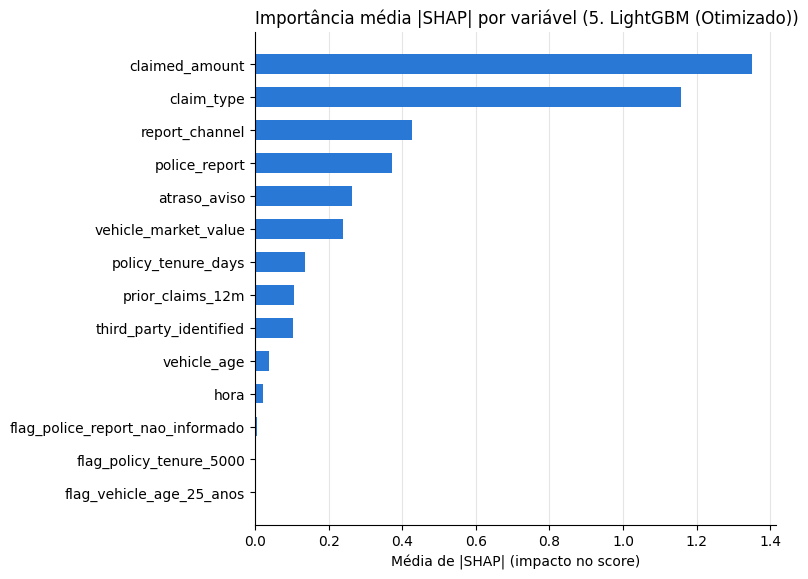

claimed_amount                      1.3495
claim_type                          1.1565
report_channel                      0.4278
police_report                       0.3722
atraso_aviso                        0.2650
vehicle_market_value                0.2380
policy_tenure_days                  0.1365
prior_claims_12m                    0.1067
third_party_identified              0.1040
vehicle_age                         0.0378
hora                                0.0226
flag_police_report_nao_informado    0.0049
flag_vehicle_age_25_anos            0.0000
flag_policy_tenure_5000             0.0000


In [78]:
warnings.filterwarnings('ignore', message='LightGBM binary classifier')   # aviso de formato do SHAP
X_teste_modelo = transformar_para_modelo(modelo_final, X_teste_bruto)
explicador = shap.TreeExplainer(modelo_final.named_steps['modelo'])
amostra = X_teste_modelo.sample(n=min(2000, len(X_teste_modelo)), random_state=SEED)
valores = np.asarray(explicador.shap_values(amostra))
if valores.ndim == 3:                                  # alguns modelos devolvem uma matriz por classe
    valores = valores[1] if valores.shape[0] == 2 else valores[..., 1]

importancia = (pd.DataFrame(np.abs(valores), columns=amostra.columns)
               .T.groupby(feature_original).sum().T.mean()
               .sort_values())

fig, ax = plt.subplots(figsize=(8, 0.35 * len(importancia) + 1))
ax.barh(importancia.index, importancia.values, height=0.6, color='#2a78d6', zorder=2)
ax.set_title(f'Importância média |SHAP| por variável ({MODELO_ESCOLHIDO})', fontsize=12, loc='left')
ax.set_xlabel('Média de |SHAP| (impacto no score)')
ax.grid(axis='x', color='#e5e5e5', zorder=0); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); plt.show()
print(importancia.sort_values(ascending=False).round(4).to_string())

In [79]:
# Visão local: os 3 sinistros com maior score no teste e as 5 variáveis que mais pesaram em cada um
top = np.argsort(-proba_final, kind='stable')[:3]
valores_top = np.asarray(explicador.shap_values(X_teste_modelo.iloc[top]))
if valores_top.ndim == 3:
    valores_top = valores_top[1] if valores_top.shape[0] == 2 else valores_top[..., 1]

for pos, (i, contrib) in enumerate(zip(top, valores_top), start=1):
    linha = X_teste_bruto.iloc[i]
    print(f"\n#{pos} {linha['claim_id']} | score {proba_final[i]:.3f} | fraude real: {int(y_teste.iloc[i])} | "
          f"{linha['claim_type']}, {linha['report_channel']}, pedido R$ {linha['claimed_amount']}")
    explicacao = (pd.DataFrame({'variável': X_teste_modelo.columns, 'valor': X_teste_modelo.iloc[i].values,
                                'SHAP': contrib})
                  .assign(abs=lambda t: t['SHAP'].abs()).nlargest(5, 'abs').drop(columns='abs'))
    print(explicacao.round(3).to_string(index=False))


#1 CLM-940947 | score 0.959 | fraude real: 0 | collision, broker, pedido R$ 90476,44
                 variável    valor  SHAP
           claimed_amount 90476.44 2.062
             atraso_aviso     8.00 1.342
     claim_type_collision     1.00 0.701
            police_report     0.00 0.324
third_party_identified_no     1.00 0.235

#2 CLM-906294 | score 0.958 | fraude real: 1 | collision, call_center, pedido R$ 4861,65
                  variável   valor  SHAP
              atraso_aviso    11.0 2.316
      claim_type_collision     1.0 0.596
report_channel_call_center     1.0 0.530
      vehicle_market_value 19600.0 0.424
             police_report     0.0 0.359

#3 CLM-799982 | score 0.957 | fraude real: 0 | collision, call_center, pedido R$ 43207,90
                  variável    valor   SHAP
            claimed_amount  43207.9  1.872
              atraso_aviso      5.0  0.973
      claim_type_collision      1.0  0.710
report_channel_call_center      1.0  0.501
      vehicle_market_value